# 05 · The champion scorecard: fit, points and first performance

## What this notebook is, and where it sits in the project

Notebook 04 binned the features on the train sample and shortlisted seven of them (D-018). This notebook builds the **champion model** of Track A: a logistic regression on the WoE values of those features, turned into a points-based scorecard, the format banks have used for decades (Siddiqi, chapters 10 and 11).

It then measures the model for the first time:

* **Ranking** (does it put risky borrowers above safe ones?) with Gini and KS, on train, test and, for the first time in the project, the **out-of-time** sample.
* **The Bondora benchmark:** Bondora's own `ProbabilityOfDefault` scored on exactly the same loans.
* **Calibration** (are the predicted default rates right on average?).

The out-of-time sample was kept blind in notebooks 03 and 04. Its results here are the honest test of the model, so nothing in the model is changed after looking at them; what they reveal goes into recommendations for later phases.

## How to read this notebook

Every step has: **Why this step**, **the code**, **What the result shows**, **Recommended action**.

The notebook reads the warehouse read-only and the files written by notebooks 03 and 04. It writes one file, `data/processed/scorecard.json` (git-ignored): the coefficients, the scaling and the points table.

## Key terms used in this notebook

| Term | Meaning |
|---|---|
| **Logistic regression** | A model that turns a weighted sum of inputs into a probability between 0 and 1. Here: the probability of default within 12 months. |
| **Coefficient** | The weight of one feature. Because positive WoE means "safer than average", every coefficient should be **negative**: more WoE, lower probability of default. |
| **p-value** | How likely a coefficient this far from zero would be if the feature had no real effect. Below 0.05 = significant. |
| **Odds** | Goods per bad. A default rate of 20% means odds of 4 to 1. |
| **Points / score** | The model rewritten as points per bin, added up into one score. Higher score = safer. |
| **PDO (points to double the odds)** | How many extra points mean the odds of being good have doubled. Here 20. |
| **Gini** | Ranking quality, from 0 (random) to 1 (perfect). Gini = 2 x AUC - 1. Consumer scorecards typically reach 0.40 to 0.60. |
| **KS** | The largest gap between the share of bads and the share of goods below the same score. Another ranking measure, 0 to 1. |
| **Bootstrap confidence interval** | Resample the loans many times and recompute Gini each time; the middle 95% of results is the interval. It shows how much of a difference between two Ginis could be chance. |
| **Calibration** | Whether predicted default rates match observed ones, on average and per score band. |
| **Benchmark** | Bondora's own `ProbabilityOfDefault`, a `benchmark` column in the registry: compared with, never used as an input. |

## Step 0. Setup

### Why this step
Load the libraries, the warehouse (read-only), the registry, and the two files from notebook 04: the fitted bins (`binning_process.pkl`) and the shortlist (`scorecard_shortlist.json`). `statsmodels` fits the logistic regression and reports coefficients with p-values, which a model reviewer expects to see; `scikit-learn` computes AUC and KS.

In [1]:
import json
import logging
import sys
import warnings
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm                          # logistic regression with p-values
from optbinning import BinningProcess
from sklearn.metrics import roc_auc_score, roc_curve  # AUC (for Gini) and the ROC curve (for KS)

warnings.filterwarnings("ignore")
logging.disable(logging.WARNING)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "pyproject.toml").exists() and (p / "src" / "pdengine").exists())
DB = ROOT / "data" / "bondora.duckdb"
PROC = ROOT / "data" / "processed"
OUT = PROC / "scorecard.json"
for f in ["model_samples.parquet", "binning_process.pkl", "scorecard_shortlist.json"]:
    assert (PROC / f).exists(), f"{f} missing: run notebooks 03 and 04 first"

try:
    from pdengine.features import add_derived
    from pdengine.registry import candidate_features, check_model_columns, load_registry
except ImportError:
    sys.path.insert(0, str(ROOT / "src"))
    from pdengine.features import add_derived
    from pdengine.registry import candidate_features, check_model_columns, load_registry

con = duckdb.connect(str(DB), read_only=True)
reg = load_registry()
bp = BinningProcess.load(str(PROC / "binning_process.pkl"))
SHORTLIST = json.loads((PROC / "scorecard_shortlist.json").read_text(encoding="utf-8"))["features"]

BLUE, GREY, ORANGE = "#2a78d6", "#b5b3ad", "#d97a2b"
plt.rcParams.update({
    "figure.figsize": (9, 3.6), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e4e3df", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8984", "axes.titleweight": "bold",
})
print("Shortlist from notebook 04:", SHORTLIST)

Shortlist from notebook 04: ['country_bureau_grade', 'NoOfPreviousLoansBeforeLoan', 'HomeOwnershipType', 'ExistingLiabilities', 'AppliedAmount', 'Education', 'income_vs_country_median']


### What the result shows
The seven shortlisted features from D-018 are loaded with their bins.

### Recommended action
None.

## Step 1. WoE matrix for all three samples

### Why this step
The model learns from WoE values, not raw values. We rebuild the raw features exactly as in notebook 04 (registry candidates plus the derived features, same column types), apply the **saved** bins, and keep only the shortlist. The leakage guard runs on the final matrix.

Bondora's `ProbabilityOfDefault` is read in the same query but kept in a separate series, `bondora_pd`. It is a `benchmark` column: `check_model_columns` would refuse it in X.

In [2]:
samples = pd.read_parquet(PROC / "model_samples.parquet").set_index("loan_key")
con.register("sample_keys", samples.reset_index()[["loan_key"]])
RAW = candidate_features(reg)
cols = ", ".join(f'"{c}"' for c in RAW)
raw = (con.execute(f"""SELECT loan_key, {cols}, "ProbabilityOfDefault" AS bondora_pd
                       FROM loans JOIN sample_keys USING (loan_key)""").df()
          .set_index("loan_key").loc[samples.index])
bondora_pd = raw.pop("bondora_pd")              # the benchmark, kept outside X
raw = add_derived(raw)

# Same column types as in notebook 04 (the bins were fitted on these types).
CATEGORICAL = ["VerificationType", "Country", "Education", "EmploymentDurationCurrentEmployer",
               "HomeOwnershipType", "ApplicationSignedWeekday",
               "CreditScoreFiAsiakasTietoRiskGrade", "country_bureau_grade"]
raw["NewCreditCustomer"] = raw["NewCreditCustomer"].astype(int)
raw["CreditScoreEeMini"] = raw["CreditScoreEeMini"].astype(float)
for c in CATEGORICAL:
    raw[c] = raw[c].astype("string").astype(object).where(raw[c].notna(), np.nan)

woe = bp.transform(raw[bp.variable_names], metric="woe").set_index(raw.index)[SHORTLIST]
check_model_columns(woe.columns, reg)            # the leakage guard, on the model matrix
y, sample, country = samples["y"], samples["sample"], raw["Country"]
is_train, is_test, is_oot = sample.eq("train"), sample.eq("test"), sample.eq("oot")
print(f"WoE matrix: {woe.shape[0]:,} loans x {woe.shape[1]} features (passed check_model_columns)")
woe[is_train].describe().T[["mean", "min", "max"]].round(3)

WoE matrix: 155,725 loans x 7 features (passed check_model_columns)


,mean,min,max
country_bureau_grade,0.100,-1.054,0.835
NoOfPreviousLoansBeforeLoan,0.041,-0.390,0.992
HomeOwnershipType,0.017,-0.362,0.342
ExistingLiabilities,0.013,-0.370,0.327
AppliedAmount,0.013,-0.273,0.319
Education,0.005,-0.200,0.197
income_vs_country_median,0.004,-0.087,0.410


### What the result shows
Every loan has a WoE value for each of the seven features. The values stay between about -1 and +1, and their train means are small (0 to 0.1), because WoE measures each bin against the train average.

### Recommended action
None.

## Step 2. Fit the logistic regression on the train sample

### Why this step
The logistic regression finds one weight (coefficient) per feature so that the weighted sum of WoE values predicts default as well as possible on the train loans.

What we check (roadmap Phase 3, Siddiqi chapter 10):

* **Sign.** WoE is positive for safer-than-average bins, so every coefficient must be negative. A positive coefficient would mean "the safer the bin, the riskier the borrower": the model would contradict its own bins. In practice that happens when a feature's information is already carried by other features.
* **Significance.** p-value below 0.05.

A feature that fails either check is removed and the model refitted. This uses only the train sample.

In [3]:
def fit(features: list[str]):
    """Logistic regression of the 12-month default flag on WoE values, train sample only."""
    return sm.Logit(y[is_train], sm.add_constant(woe.loc[is_train, features])).fit(disp=0)


def coef_table(model) -> pd.DataFrame:
    t = model.summary2().tables[1][["Coef.", "Std.Err.", "P>|z|"]].rename(
        columns={"Coef.": "coef", "Std.Err.": "std_err", "P>|z|": "p_value"})
    t["expected_sign"] = np.where(t.index == "const", "", "negative")
    t["passes"] = np.where(t.index == "const", True, (t["coef"] < 0) & (t["p_value"] < 0.05))
    return t.round(4)


first = fit(SHORTLIST)
coef_table(first)

,coef,std_err,p_value,expected_sign,passes
const,-0.7838,0.0085,0.00,,True
country_bureau_grade,-0.8582,0.0119,0.00,negative,True
NoOfPreviousLoansBeforeLoan,-0.3896,0.0258,0.00,negative,True
HomeOwnershipType,-0.5548,0.0283,0.00,negative,True
ExistingLiabilities,0.0555,0.0385,0.15,negative,False
AppliedAmount,-0.2064,0.0354,0.00,negative,True
Education,-0.3389,0.0525,0.00,negative,True
income_vs_country_median,-0.5905,0.0595,0.00,negative,True


### What the result shows
* Six features have negative, highly significant coefficients.
* **`ExistingLiabilities` fails both checks:** its coefficient is slightly positive (+0.06) and not significant (p = 0.15). On its own (notebook 04) it ranks risk sensibly, but once the number of previous Bondora loans and home ownership are in the model, it has nothing left to add. Its WoE correlates 0.62 with the previous-loan count.

### Recommended action
Remove `ExistingLiabilities` and refit (D-019).

## Step 3. The final model, and a stability check of its weights

### Why this step
Refit on the six remaining features. Then a robustness check that uses only the **test** sample (never the out-of-time sample): fit the same model on the test loans alone. If the weights are real, they should come out similar, with the same signs. Weights that change a lot between two random halves of the same years would mean the model is fragile.

In [4]:
FEATURES = [f for f in SHORTLIST if f != "ExistingLiabilities"]
model = fit(FEATURES)
final = coef_table(model)

# Same model fitted on the test sample only, to compare the weights.
on_test = sm.Logit(y[is_test], sm.add_constant(woe.loc[is_test, FEATURES])).fit(disp=0)
final["coef_fitted_on_test"] = on_test.params.round(4)
print(f"All coefficients pass: {final['passes'].all()}   pseudo R-squared (train): {model.prsquared:.3f}")
final

All coefficients pass: True   pseudo R-squared (train): 0.108


,coef,std_err,p_value,expected_sign,passes,coef_fitted_on_test
const,-0.7838,0.0085,0.0,,True,-0.7863
country_bureau_grade,-0.8582,0.0119,0.0,negative,True,-0.8599
NoOfPreviousLoansBeforeLoan,-0.3696,0.0218,0.0,negative,True,-0.3518
HomeOwnershipType,-0.5526,0.0283,0.0,negative,True,-0.5613
AppliedAmount,-0.2048,0.0353,0.0,negative,True,-0.1614
Education,-0.3397,0.0525,0.0,negative,True,-0.2259
income_vs_country_median,-0.5868,0.0595,0.0,negative,True,-0.6317


### What the result shows
* All six coefficients are negative and significant (every p-value is below 0.001).
* The weights fitted on the test sample alone are close to the train weights and have the same signs. The model is not fragile.
* `country_bureau_grade` has the largest weight (about -0.86), then relative income and home ownership (about -0.55 to -0.59), previous loans, education and the applied amount. Education's weight is the least stable (-0.34 on train, -0.23 on test), which fits its low IV.
* Removing `ExistingLiabilities` changed the other weights very little, which confirms it was redundant.

### Recommended action
Accept this model as the champion scorecard (D-019).

## Step 4. Turn the model into a points scorecard

### Why this step
A logistic regression gives a probability. A credit officer works with **points**: each bin of each feature is worth a number of points, the points are added up, and a higher total means a safer applicant. The points are a rescaling of the same model; the ranking does not change.

The scaling (Siddiqi, chapter 11):

* **600 points = good:bad odds of 30 to 1** (a default rate of about 3.2%),
* **PDO = 20:** every 20 extra points double the odds of being good.

So `factor = 20 / ln(2)` and `offset = 600 - factor x ln(30)`. With n features, intercept a and coefficient b, the points of a bin with weight of evidence WoE are:

`points = offset / n - factor x (b x WoE + a / n)`

The intercept and offset are spread evenly over the features, so every bin's points can be read on their own. The three numbers 600, 30 and 20 are a convention; any choice gives the same ranking.

In [5]:
BASE_SCORE, BASE_ODDS, PDO = 600, 30, 20
factor = PDO / np.log(2)
offset = BASE_SCORE - factor * np.log(BASE_ODDS)
a, n = model.params["const"], len(FEATURES)

rows = []
for f in FEATURES:
    t = bp.get_binned_variable(f).binning_table.build().drop(index="Totals")
    t = t[t["Count"] > 0]
    for _, r in t.iterrows():
        rows.append({"feature": f, "bin": str(r["Bin"]), "woe": r["WoE"], "event_rate": r["Event rate"],
                     "points": offset / n - factor * (model.params[f] * r["WoE"] + a / n)})
points = pd.DataFrame(rows)
points["points"] = points["points"].round().astype(int)


def score(w: pd.DataFrame) -> pd.Series:
    """Exact score of each loan from its WoE values (same formula, before rounding)."""
    logit = a + (w[FEATURES] * model.params[FEATURES]).sum(axis=1)
    return offset - factor * logit


scores = score(woe)
pd_model = model.predict(sm.add_constant(woe[FEATURES]))   # probability of default
points.round({"woe": 3, "event_rate": 3})

,feature,bin,woe,event_rate,points
0,country_bureau_grade,['EE_missing' 'FI_8' 'EE_1000'],0.835,0.165,108
1,country_bureau_grade,['EE_900' 'FI_1' 'EE_800' 'EE_700' 'FI_RL1' 'E...,0.234,0.266,93
2,country_bureau_grade,['FI_2' 'FI_6' 'FI_3' 'FI_RL2'],-0.343,0.392,79
3,country_bureau_grade,['FI_4'],-0.689,0.476,70
4,country_bureau_grade,['FI_5' 'FI_RL4' 'FI_missing' 'ES' 'FI_7' 'FI_...,-1.054,0.567,61
5,NoOfPreviousLoansBeforeLoan,"(-inf, 0.50)",-0.390,0.403,83
6,NoOfPreviousLoansBeforeLoan,"[0.50, 1.50)",0.097,0.293,88
7,NoOfPreviousLoansBeforeLoan,"[1.50, 2.50)",0.279,0.257,90
8,NoOfPreviousLoansBeforeLoan,"[2.50, 3.50)",0.499,0.217,93
9,NoOfPreviousLoansBeforeLoan,"[3.50, 5.50)",0.661,0.191,94


In [6]:
# How the scores spread, and two example applicants from the test sample.
print(scores[is_train].describe(percentiles=[0.05, 0.5, 0.95]).round(0).to_string())
for label, loan in [("safest test applicant", scores[is_test].idxmax()),
                    ("riskiest test applicant", scores[is_test].idxmin())]:
    print(f"\n{label}: score {scores[loan]:.0f}, PD {pd_model[loan]:.1%}, defaulted: {bool(y[loan])}")
    print(raw.loc[loan, FEATURES].to_string())

count    75302.0
mean       528.0
std         24.0
min        484.0
5%         490.0
50%        534.0
95%        560.0
max        572.0

safest test applicant: score 572, PD 8.1%, defaulted: False
country_bureau_grade           EE_1000
NoOfPreviousLoansBeforeLoan          6
HomeOwnershipType                    1
AppliedAmount                    530.0
Education                            4
income_vs_country_median          3.28

riskiest test applicant: score 483, PD 65.5%, defaulted: True
country_bureau_grade                 ES
NoOfPreviousLoansBeforeLoan           0
HomeOwnershipType                     3
AppliedAmount                    9035.0
Education                             1
income_vs_country_median       1.019259


### What the result shows
* The scorecard has 28 bins across six features, each with its points. For example, an applicant in the safest `country_bureau_grade` group (mainly top-grade Estonian borrowers) gets far more points than one in the riskiest group (Spain and the weakest Finnish grades); six or more previous Bondora loans earn more points than none.
* Train scores range from 484 to 572, with a median of 534. That is far below 600 because Bondora's borrowers are risky: a typical default rate of 31% means odds of about 2 to 1, not 30 to 1.
* The two example applicants show how the points add up from readable facts: country and bureau grade, previous loans, home, income, education and amount.

### Recommended action
* Keep this scaling. Risk grades (score bands) are defined in Phase 4, after recalibration (step 7), so they map to realistic default rates.
* Keep the points table with the model documentation: it is the scorecard a credit officer would see.

## Step 5. Ranking performance: train, test and out-of-time, against Bondora

### Why this step
Gini and KS measure how well the score ranks borrowers. We compute them on:

* **train** (the loans the model learned from),
* **test** (same years, unseen loans): a large gap to train would mean overfitting,
* **out-of-time** (2020 to July 2021, unseen period): the headline result. **This is the first time the project looks at default outcomes in this sample.**

Bondora's own `ProbabilityOfDefault` is scored on exactly the same loans. Bootstrap confidence intervals (500 resamples) show whether the gap between the two models is larger than chance.

In [7]:
def gini(target, score_) -> float:
    return 2 * roc_auc_score(target, score_) - 1


def ks(target, score_) -> float:
    fpr, tpr, _ = roc_curve(target, score_)
    return float((tpr - fpr).max())


def gini_ci(target, score_, n_boot=500, seed=42):
    """95% bootstrap interval of the Gini: resample loans with replacement, recompute."""
    rng, t, s_ = np.random.default_rng(seed), np.asarray(target), np.asarray(score_)
    g = [gini(t[i], s_[i]) for i in (rng.integers(0, len(t), len(t)) for _ in range(n_boot))]
    return np.percentile(g, [2.5, 97.5])


perf = []
for name, mask in [("train", is_train), ("test", is_test), ("oot", is_oot)]:
    for model_name, s_ in [("scorecard", pd_model), ("Bondora PD", bondora_pd)]:
        lo, hi = gini_ci(y[mask], s_[mask])
        perf.append({"sample": name, "model": model_name, "gini": gini(y[mask], s_[mask]),
                     "gini_low": lo, "gini_high": hi, "ks": ks(y[mask], s_[mask])})
perf = pd.DataFrame(perf).round(3)
perf

,sample,model,gini,gini_low,gini_high,ks
0,train,scorecard,0.443,0.435,0.450,0.345
1,train,Bondora PD,0.418,0.410,0.426,0.315
2,test,scorecard,0.440,0.428,0.452,0.340
3,test,Bondora PD,0.418,0.406,0.430,0.317
4,oot,scorecard,0.349,0.336,0.364,0.252
5,oot,Bondora PD,0.405,0.392,0.418,0.300


In [8]:
# Is the scorecard really better or worse than Bondora? Paired bootstrap of the DIFFERENCE:
# the same resampled loans are scored by both models, so the comparison is like for like.
def gini_difference(mask, n_boot=500, seed=42):
    rng = np.random.default_rng(seed)
    t, a_, b_ = y[mask].to_numpy(), pd_model[mask].to_numpy(), bondora_pd[mask].to_numpy()
    diffs = []
    for _ in range(n_boot):
        i = rng.integers(0, len(t), len(t))
        diffs.append(gini(t[i], a_[i]) - gini(t[i], b_[i]))
    return gini(t, a_) - gini(t, b_), *np.percentile(diffs, [2.5, 97.5])


pd.DataFrame([dict(zip(["sample", "scorecard_minus_bondora", "low", "high"], (n, *gini_difference(m))))
              for n, m in [("test", is_test), ("oot", is_oot)]]).round(3)

,sample,scorecard_minus_bondora,low,high
0,test,0.022,0.012,0.033
1,oot,-0.056,-0.075,-0.038


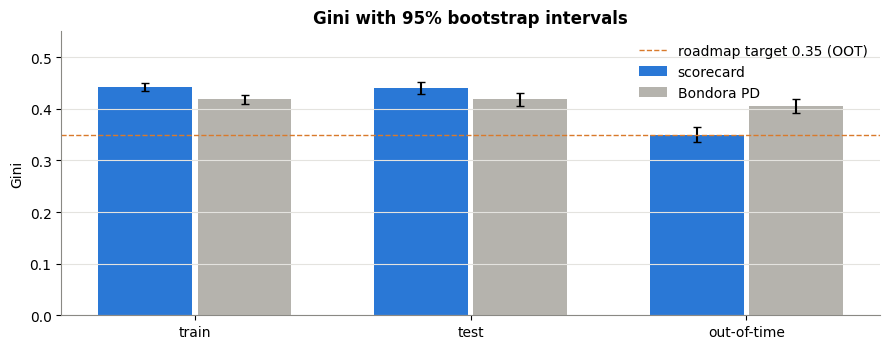

In [9]:
fig, ax = plt.subplots()
xs = np.arange(3)
for k, (model_name, colour) in enumerate([("scorecard", BLUE), ("Bondora PD", GREY)]):
    p = perf[perf["model"] == model_name].set_index("sample").loc[["train", "test", "oot"]]
    ax.bar(xs + (k - 0.5) * 0.36, p["gini"], width=0.34, color=colour, label=model_name,
           yerr=[p["gini"] - p["gini_low"], p["gini_high"] - p["gini"]], capsize=3)
ax.axhline(0.35, color=ORANGE, linewidth=1, linestyle="--", label="roadmap target 0.35 (OOT)")
ax.set_xticks(xs, ["train", "test", "out-of-time"])
ax.set_ylabel("Gini")
ax.set_ylim(0, 0.55)
ax.set_title("Gini with 95% bootstrap intervals")
ax.legend(frameon=False, loc="upper right")
plt.tight_layout(); plt.show()

### What the result shows
* **Train 0.443, test 0.440:** almost no gap, so the model is not overfitted.
* **On the test sample the scorecard ranks slightly better than Bondora's PD:** 0.440 against 0.418. The separate intervals touch, but the paired comparison (same loans scored by both models) puts the difference at about +0.02 with an interval that stays above zero. Six transparent application features rank 2016 to 2019 borrowers at least as well as the lender's own model.
* **Out of time the order reverses:** the scorecard drops to **0.349** (0.336 to 0.364), Bondora's PD holds up better at **0.405** (0.392 to 0.418), a difference of about -0.06 that is clearly not chance. The scorecard sits right at the roadmap target of 0.35: the interval contains it, but the point estimate is just below it.
* KS follows the same pattern (0.34 on test, 0.25 out of time).

### Recommended action
* Report the out-of-time Gini as **0.35 (0.34 to 0.36)**, "at the target", and state that Bondora's PD ranks out-of-time loans better.
* Do not tune the model to the out-of-time result. Step 6 explains the drop; the fixes belong to later, documented steps.

## Step 6. Why does the Gini fall out of time?

### Why this step
A drop from 0.44 to 0.35 needs an explanation before anyone trusts the model. Two candidate reasons:

1. **The model ranks borrowers worse inside each country** (the features lost their meaning), or
2. **The country mix and the gaps between countries changed**, so the country part of the score, the biggest part, separates less.

Computing the Gini **within** each country separates the two. The default rate per country in each sample shows the second effect directly. We also check the ranking on test loans issued before and after the June 2017 form change (a recommendation from notebook 04).

In [10]:
rows = []
for name, mask in [("test", is_test), ("oot", is_oot)]:
    for c in ["EE", "FI", "ES"]:
        m = mask & country.eq(c)
        rows.append({"sample": name, "country": c, "loans": int(m.sum()), "default_rate": y[m].mean(),
                     "gini_scorecard": gini(y[m], pd_model[m]), "gini_bondora": gini(y[m], bondora_pd[m])})
within = pd.DataFrame(rows).round(3)
display(within)

june_2017 = samples["issue_date"] < pd.Timestamp("2017-06-01")
for label, m in [("test, before June 2017", is_test & june_2017), ("test, from June 2017", is_test & ~june_2017)]:
    print(f"{label}: {m.sum():,} loans, Gini {gini(y[m], pd_model[m]):.3f}")

,sample,country,loans,default_rate,gini_scorecard,gini_bondora
0,test,EE,18423,0.186,0.205,0.256
1,test,FI,8118,0.418,0.179,0.247
2,test,ES,5732,0.576,0.202,0.225
3,oot,EE,34888,0.113,0.313,0.359
4,oot,FI,10266,0.140,0.156,0.284
5,oot,ES,2996,0.512,0.114,0.162


test, before June 2017: 4,673 loans, Gini 0.470
test, from June 2017: 27,600 loans, Gini 0.434


### What the result shows
* **The gap between countries narrowed.** On the test sample (2016 to 2019) the default rates are about 19% in Estonia, 42% in Finland and 58% in Spain. Out of time, Finland drops to **14%**, close to Estonia's 11%. The score still separates Finnish from Estonian borrowers as strongly as before, but the outcomes no longer differ much: that is lost ranking power in the pooled Gini. Spain also shrinks from 18% of test loans to 6% of out-of-time loans.
* **Inside Estonia the scorecard ranks better out of time than in test** (Gini 0.21 to 0.31). Inside Finland and Spain it ranks worse (0.18 to 0.15; 0.20 to 0.12; Spain has only three months of out-of-time lending).
* **Bondora's PD ranks better inside every country**, in both samples. It has information this project cannot use (its own repayment history with the borrower, bureau data beyond the Kaggle fields, and the fields dropped in 2017), so this gap is expected for a model built only on today's application fields.
* **Before and after June 2017** the test Gini is 0.47 and 0.43: the scorecard works on both form versions, slightly better on the older one.

So the drop is mostly reason 2: the world changed between countries, especially Finland, which is the kind of change an out-of-time test exists to reveal.

### Recommended action
* State this explanation with the out-of-time result.
* In Phase 4, recalibrate the scorecard per country (Finland's default level changed the most) and report Gini per country.
* The LightGBM challenger (next notebook) uses the same inputs; if it also falls to about 0.35 out of time, the limit is the data, not the scorecard method.

## Step 7. Calibration: are the predicted default rates right?

### Why this step
Ranking is one half of a PD model; the other is the level. IFRS 9 provisions and pricing use the PD itself, so a model that ranks well but predicts 27% when 14% happen would set aside twice the money needed.

We compare the average predicted PD with the observed default rate per sample, and then per score decile (ten groups of equal size from safest to riskiest).

,mean_predicted_pd,observed_default_rate,bondora_mean_pd,ratio_predicted_to_observed
sample,,,,
train,0.314,0.314,0.266,1.000
test,0.314,0.314,0.264,1.003
oot,0.270,0.144,0.174,1.877


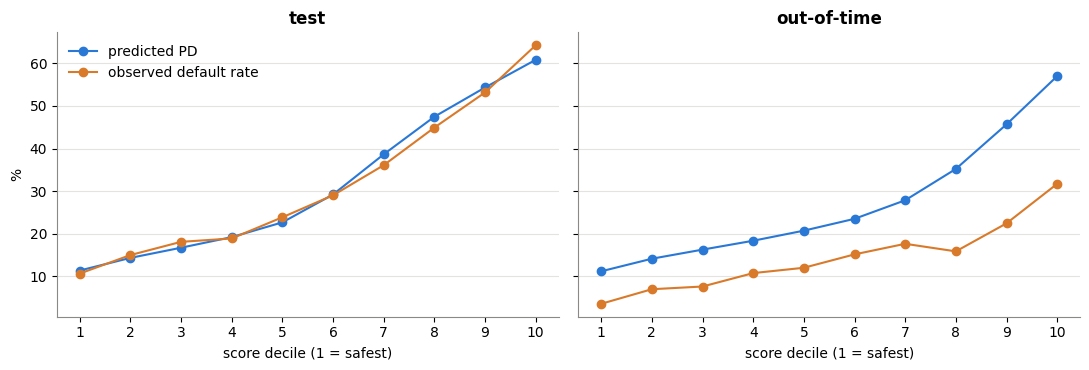

In [11]:
calib = pd.DataFrame([{"sample": n, "mean_predicted_pd": pd_model[m].mean(), "observed_default_rate": y[m].mean(),
                       "bondora_mean_pd": bondora_pd[m].mean()}
                      for n, m in [("train", is_train), ("test", is_test), ("oot", is_oot)]]).set_index("sample")
calib["ratio_predicted_to_observed"] = calib["mean_predicted_pd"] / calib["observed_default_rate"]
display(calib.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, (name, mask) in zip(axes, [("test", is_test), ("out-of-time", is_oot)]):
    d = pd.DataFrame({"pd": pd_model[mask], "y": y[mask]})
    d["decile"] = pd.qcut(d["pd"], 10, labels=False) + 1
    g = d.groupby("decile").agg(predicted=("pd", "mean"), observed=("y", "mean")) * 100
    ax.plot(g.index, g["predicted"], color=BLUE, marker="o", label="predicted PD")
    ax.plot(g.index, g["observed"], color=ORANGE, marker="o", label="observed default rate")
    ax.set_title(name)
    ax.set_xlabel("score decile (1 = safest)")
    ax.set_xticks(range(1, 11))
axes[0].set_ylabel("%")
axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()

### What the result shows
* **Train and test: well calibrated.** The mean predicted PD equals the observed rate (31.4%), and the two lines match in every decile. That is expected in-time.
* **Out of time: about twice too high.** The model predicts 27% on average; 14.4% happen (ratio about 1.9). The gap is present in every decile, but the order is mostly kept (one small dip at decile 8): decile 10 still defaults most, decile 1 least. Bondora's PD (17% on average) is closer but also too high.
* This is the drift the roadmap anticipated (default rates fell about threefold after 2019): a model built on 2016 to 2019 overestimates risk on later loans.

### Recommended action
* Do not use these PDs directly for decisions or ECL. Recalibrate first (roadmap D10): keep the score, re-map it to PDs on recent data, per country (Phase 4).
* Report out-of-time calibration before and after recalibration in the model documentation.

## Step 8. Save the scorecard

### Why this step
The challenger notebook, the recalibration in Phase 4 and the scoring API all need the same model. We save the features, coefficients, scaling and points table in one JSON file. The bins stay in `binning_process.pkl` from notebook 04.

In [12]:
OUT.write_text(json.dumps({
    "model": "WoE logistic scorecard (champion), D-019",
    "features": FEATURES,
    "intercept": float(a),
    "coefficients": {f: float(model.params[f]) for f in FEATURES},
    "scaling": {"base_score": BASE_SCORE, "base_odds": BASE_ODDS, "pdo": PDO,
                "factor": float(factor), "offset": float(offset)},
    "points": points[["feature", "bin", "points"]].to_dict(orient="records"),
    "bins": "data/processed/binning_process.pkl",
    "trained_on": "train sample, data/processed/model_samples.parquet",
}, indent=2), encoding="utf-8")

saved = json.loads(OUT.read_text(encoding="utf-8"))                      # read back and check
logit = saved["intercept"] + sum(woe[f] * c for f, c in saved["coefficients"].items())
assert np.allclose(1 / (1 + np.exp(-logit)), pd_model)
print(f"Wrote {OUT.relative_to(ROOT)}: {len(saved['features'])} features, {len(saved['points'])} bins")

Wrote data\processed\scorecard.json: 6 features, 28 bins


### What the result shows
The file reproduces the model's PDs exactly.

### Recommended action
Later, move the scoring formula into `src/pdengine/` with a test, so the API and the notebooks score loans with one function.

## Step 9. Summary of findings and recommended actions

### Findings

| # | Area | Finding | Action | Decision |
|---|---|---|---|---|
| 1 | Coefficients | `ExistingLiabilities` had the wrong sign and p = 0.15 once previous loans were in the model. | Removed; six features left. | D-019 |
| 2 | Final model | Six negative, significant coefficients; weights refitted on the test sample agree. | Champion scorecard. | D-019 |
| 3 | Points | 600 points at odds 30:1, PDO 20; train scores 484 to 572 (median 534). | Grades defined after recalibration (Phase 4). | D-019 |
| 4 | In-time ranking | Gini 0.443 train, 0.440 test: no overfitting. Slightly above Bondora's PD on test (0.418; paired difference about +0.02). | | |
| 5 | Out-of-time ranking | Gini 0.349 (0.336 to 0.364), at the 0.35 target; Bondora's PD 0.405 (paired difference about -0.06). | Report honestly, with the reason. | |
| 6 | Reason for the drop | Finland's default rate fell from 42% to 14%, close to Estonia; Spain shrank. Within Estonia the Gini rose. | Per-country recalibration and reporting in Phase 4. | |
| 7 | Form change | Test Gini 0.47 before June 2017, 0.43 after. | No action. | |
| 8 | Calibration | Exact in-time; out of time the PDs are about 1.9 times too high, in every decile. | Recalibrate before any use (roadmap D10). | |

### What this means for the next phase

The champion scorecard exists and is documented. Next: the **LightGBM challenger and the full benchmark comparison** on the same samples (roadmap Phase 3), then **recalibration and risk grades** in Phase 4.

### The scorecard in one paragraph (for my video)

I fitted a logistic regression on six binned features and turned it into a points scorecard: each answer on the application earns points, and more points means safer. Every weight points the way a credit officer would expect, and one feature that contradicted the others was removed. On loans from the same years the model never saw, it ranks borrowers with a Gini of 0.44, slightly better than Bondora's own model on the same loans. Then I opened the out-of-time test for the first time: on 2020 and 2021 loans the Gini falls to 0.35, right at my target, while Bondora's model holds up better. The reason is not that the scorecard broke: Finland's default rate fell from 42% to 14% after 2019, so the country gap, my strongest signal, shrank. The model also predicts about twice the defaults that actually happened, which is why the next step is recalibration, not deployment.

In [13]:
con.close()   # release the warehouse file